# 02. Exploratory Data Analysis (EDA)

This notebook explores the OULAD dataset through descriptive statistics and visualizations to identify patterns in student demographics, learning activities, assessment performance, and academic outcomes.
Dưới đây là bản dịch chuẩn xác, mang văn phong kỹ thuật và học thuật dành cho đề cương phân tích (Analysis Outline / EDA Pipeline) trong Data Science:

1. Dataset Overview
Inspect table dimensions (shape), data types, and summary descriptive statistics across all tables.

2. Student Demographics
Explore gender distribution, age groups, educational attainment levels, geographic regions, and disability status.

3. Assessment Performance
Analyze assessment scores, assessment types, and their respective weightings.

4. Learning Behavior
Examine clickstream volume, interaction frequency, and student learning activities on the VLE.

5. Academic Outcomes
Analyze `final_result` and investigate its relationships with student demographic profiles, assessment scores, and online learning behaviors.

### 1. Data Overview.

In [24]:

# 1. Import libraries and load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("raw_data")

data = {
    file.stem: pd.read_csv(file)
    for file in DATA_DIR.glob("*.csv")
}

print("Loaded tables:", list(data.keys()))


Loaded tables: ['assessments', 'courses', 'studentAssessment', 'studentInfo', 'studentRegistration', 'studentVle', 'vle']


In [25]:

# 2. Dataset overview

overview = pd.DataFrame([
    {
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    }
    for name, df in data.items()
])

display(overview)


,Table,Rows,Columns
0,assessments,206,6
1,courses,22,3
2,studentAssessment,173912,5
3,studentInfo,32593,12
4,studentRegistration,32593,5
5,studentVle,10655280,6
6,vle,6364,6


### 2. Student Demographics

In [26]:

# 2.1. Student Demographics

student_info = data["studentInfo"]

demographic_columns = [
    "gender",
    "age_band",
    "highest_education",
    "region",
    "imd_band",
    "disability"
]

for column in demographic_columns:
    print(f"\n--- {column} ---")

    counts = student_info[column].value_counts(dropna=False)
    percentages = (
        student_info[column]
        .value_counts(dropna=False, normalize=True) * 100
    )

    summary = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages.round(2)
    })

    display(summary)



--- gender ---


,Count,Percentage
gender,,
M,17875,54.84
F,14718,45.16



--- age_band ---


,Count,Percentage
age_band,,
0-35,22944,70.40
35-55,9433,28.94
55<=,216,0.66



--- highest_education ---


...

,Count,Percentage
region,,
Scotland,3446,10.57
East Anglian Region,3340,10.25
London Region,3216,9.87
South Region,3092,9.49
North Western Region,2906,8.92
West Midlands Region,2582,7.92
South West Region,2436,7.47
East Midlands Region,2365,7.26
South East Region,2111,6.48



--- imd_band ---


,Count,Percentage
imd_band,,
20-30%,3654,11.21
30-40%,3539,10.86
10-20,3516,10.79
0-10%,3311,10.16
40-50%,3256,9.99
50-60%,3124,9.58
60-70%,2905,8.91
70-80%,2879,8.83
80-90%,2762,8.47



--- disability ---


,Count,Percentage
disability,,
N,29429,90.29
Y,3164,9.71


- Academic Background.

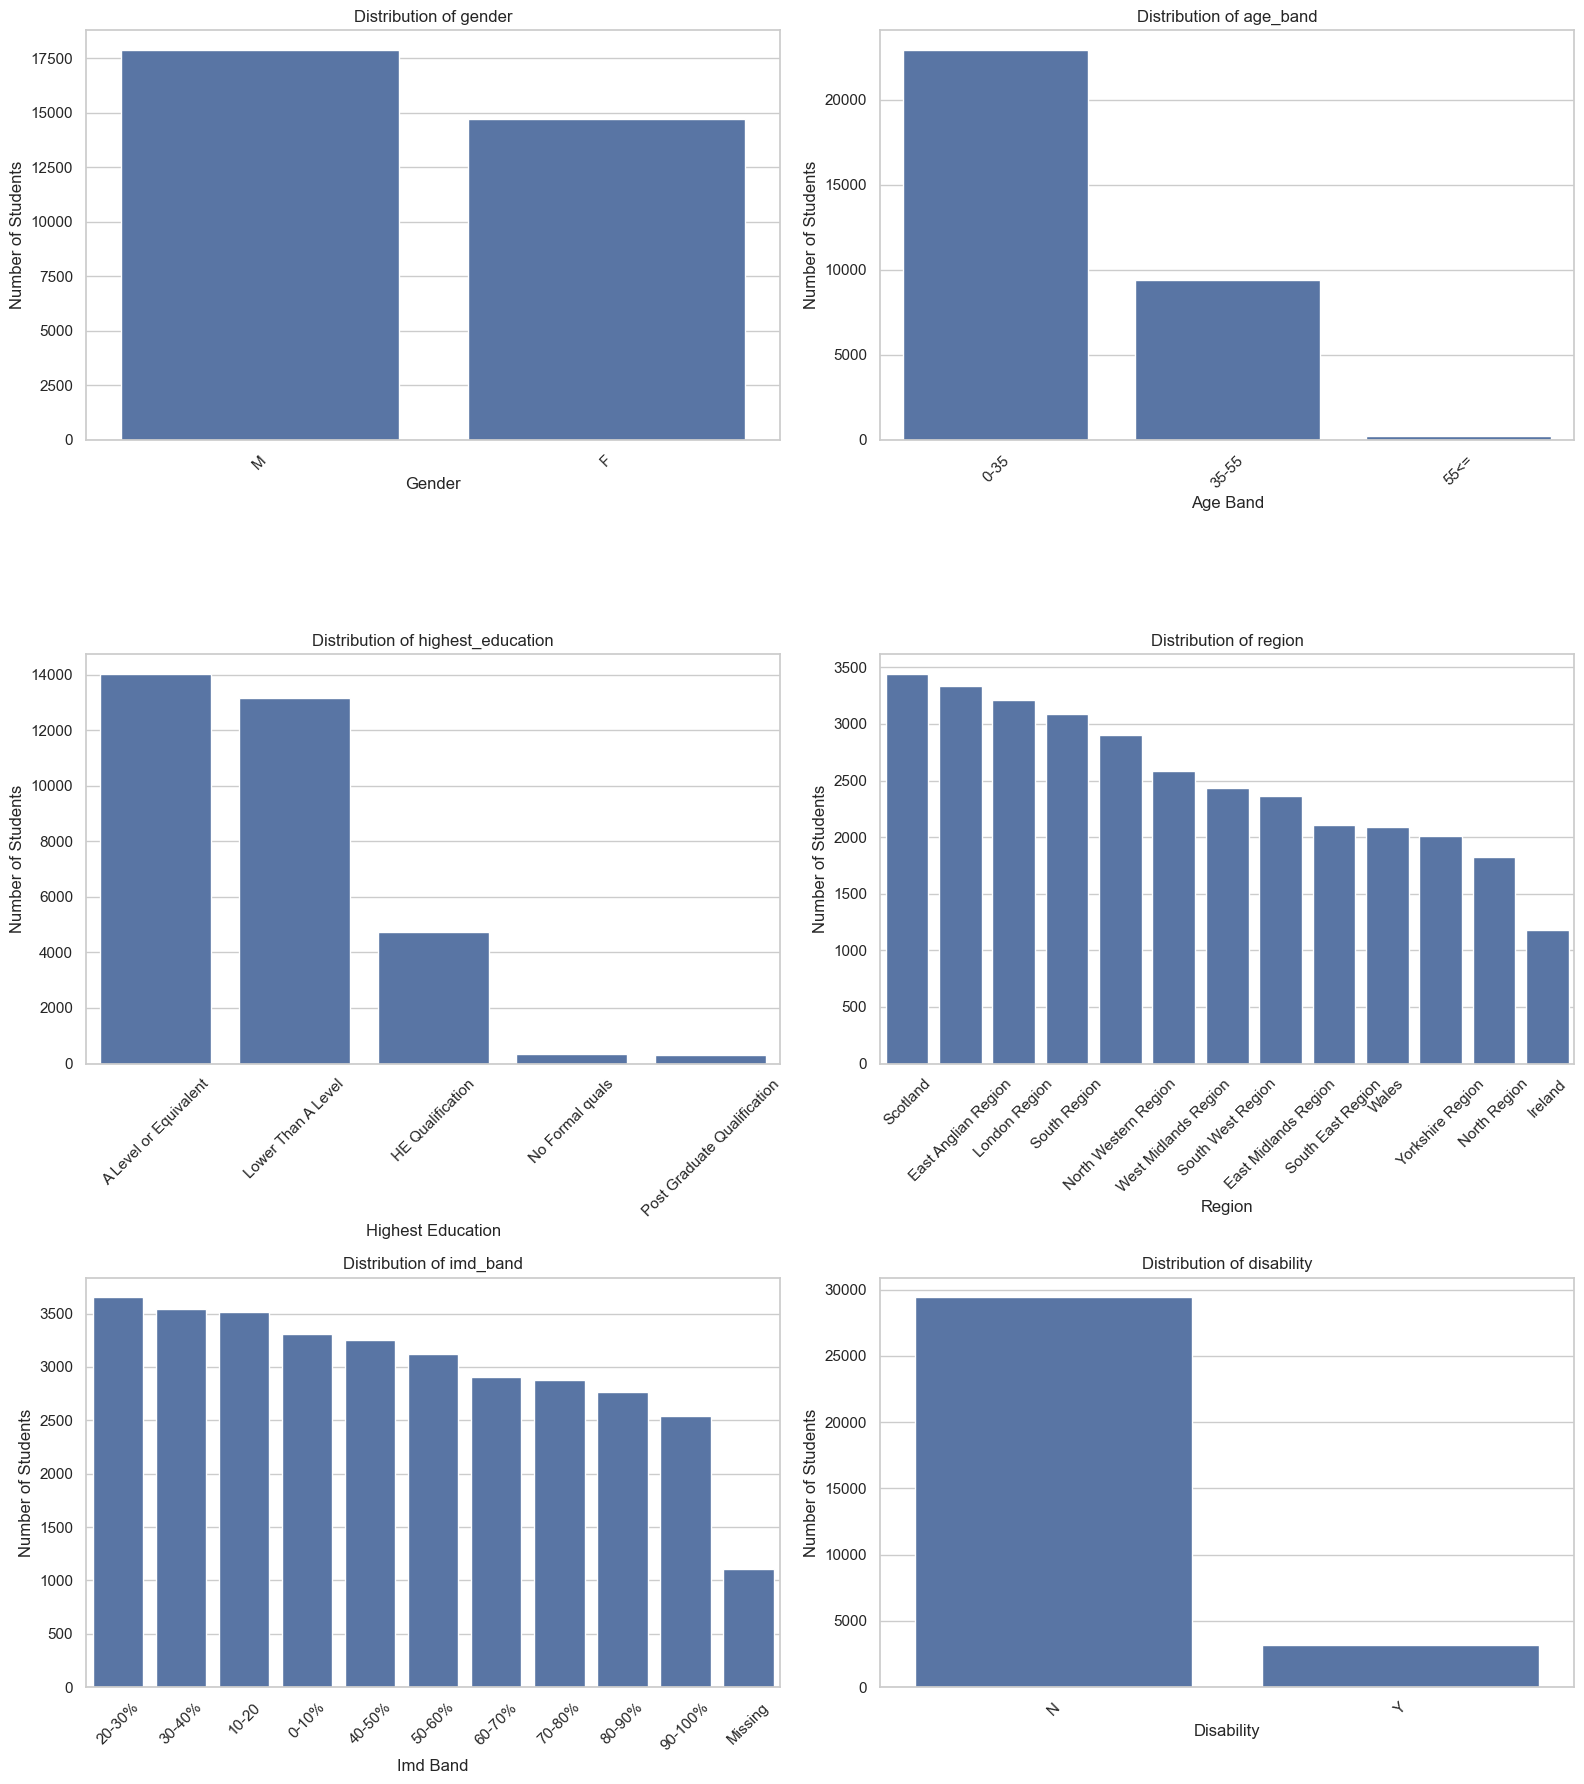

In [27]:

# 2.2. Student Demographics Visualization

demographic_columns = [
    "gender",
    "age_band",
    "highest_education",
    "region",
    "imd_band",
    "disability"
]

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for i, column in enumerate(demographic_columns):
    counts = (
        data["studentInfo"][column]
        .fillna("Missing")
        .value_counts()
    )

    sns.barplot(
        x=counts.index,
        y=counts.values,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column.replace("_", " ").title())
    axes[i].set_ylabel("Number of Students")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [28]:

# 3.1. Descriptive Statistics

academic_columns = [
    "num_of_prev_attempts",
    "studied_credits"
]

display(
    data["studentInfo"][academic_columns].describe().T
)


,count,mean,std,min,25%,50%,75%,max
num_of_prev_attempts,32593.0,0.163225,0.479758,0.0,0.0,0.0,0.0,6.0
studied_credits,32593.0,79.758691,41.071900,30.0,60.0,60.0,120.0,655.0


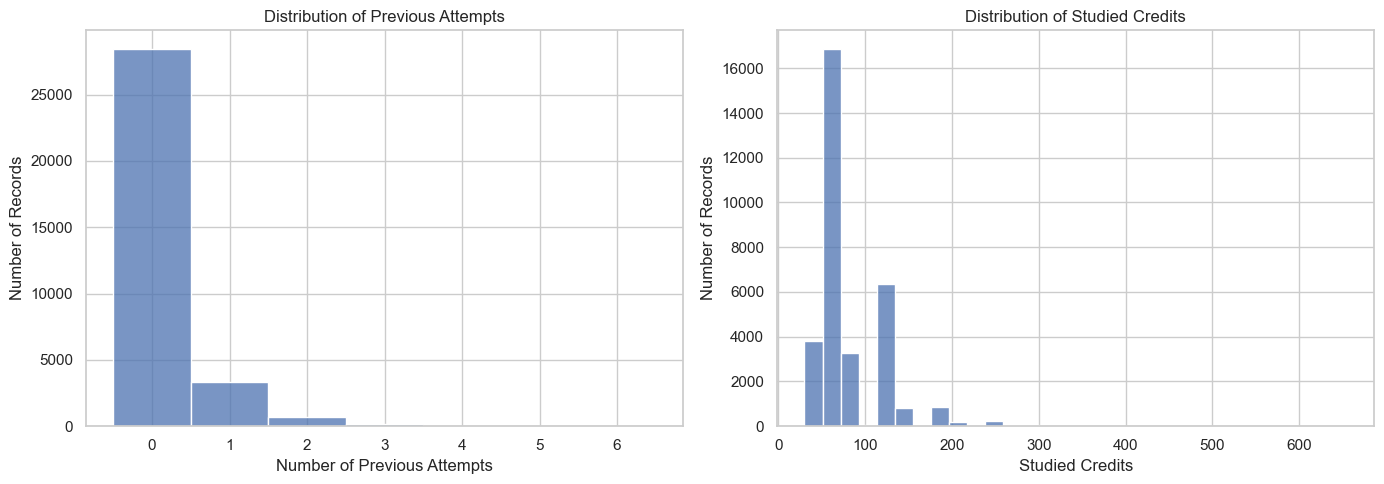

In [29]:

# 3.2. Academic Background Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=data["studentInfo"],
    x="num_of_prev_attempts",
    discrete=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Previous Attempts")
axes[0].set_xlabel("Number of Previous Attempts")
axes[0].set_ylabel("Number of Records")

sns.histplot(
    data=data["studentInfo"],
    x="studied_credits",
    bins=30,
    ax=axes[1]
)
axes[1].set_title("Distribution of Studied Credits")
axes[1].set_xlabel("Studied Credits")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()



The distribution of `num_of_prev_attempts` shows that most students have zero previous attempts for the corresponding course. The mean is approximately 0.16, while the median is zero. The maximum value is six attempts, indicating that only a small proportion of students have previous attempts.

For `studied_credits`, the mean is approximately 79.76 credits, compared with a median of 60 credits. The distribution is right-skewed, with most observations concentrated at lower credit values and a small number of observations reaching much higher values.

These findings indicate differences in students' academic histories and registered study loads. The extreme values in `studied_credits` should be investigated further before deciding whether any data treatment is necessary.

### 3. Assessment Performance.

Score statistics:


,score
count,173739.000000
mean,75.799573
std,18.798107
min,0.000000
25%,65.000000
50%,80.000000
75%,90.000000
max,100.000000


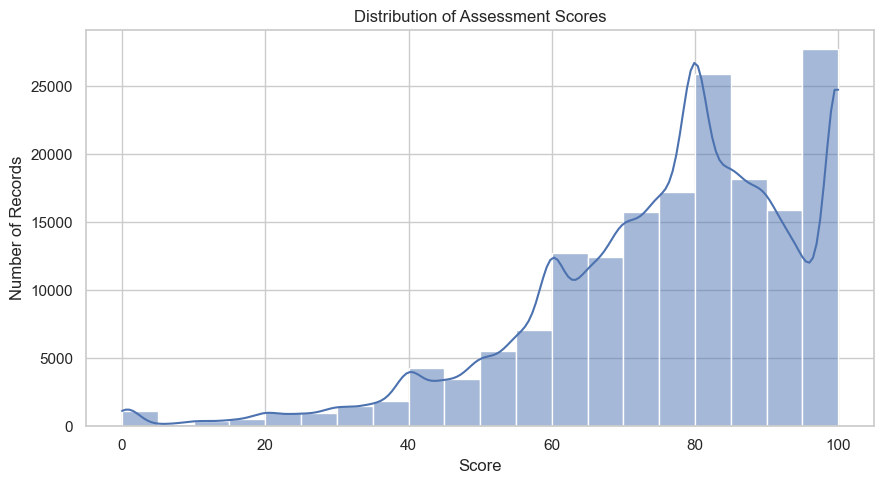

In [30]:

# 4.1. Assessment Score Distribution

student_assessment = data["studentAssessment"]

print("Score statistics:")
display(student_assessment["score"].describe().to_frame())

plt.figure(figsize=(9, 5))
sns.histplot(
    data=student_assessment,
    x="score",
    bins=20,
    kde=True
)

plt.title("Distribution of Assessment Scores")
plt.xlabel("Score")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


The histogram shows that scores are concentrated in the higher range, particularly between 60 and 100, with noticeable peaks around 80 and 100. The score distribution is negatively skewed (left-skewed), with most scores concentrated in the higher range and a longer tail extending toward lower scores.

,Count
assessment_type,
TMA,106
CMA,76
Exam,24


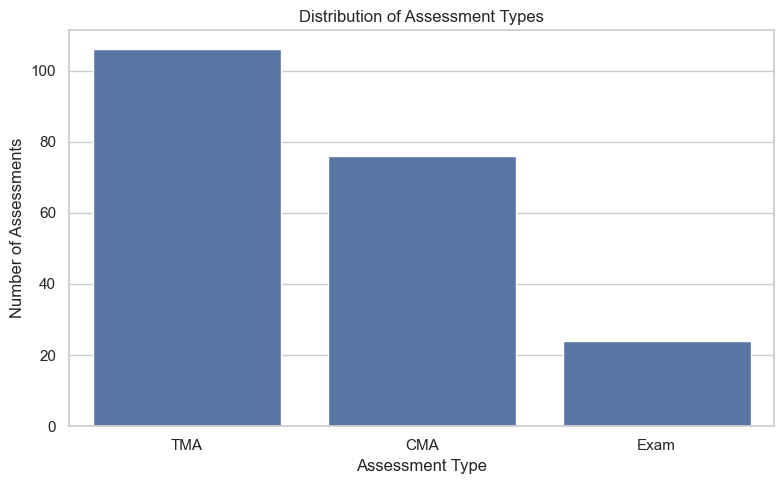

In [31]:

# 4.2. Assessment Type Distribution

assessments = data["assessments"]

assessment_counts = assessments["assessment_type"].value_counts()

display(
    assessment_counts.rename("Count").to_frame()
)

plt.figure(figsize=(8, 5))
sns.countplot(
    data=assessments,
    x="assessment_type",
    order=assessment_counts.index
)

plt.title("Distribution of Assessment Types")
plt.xlabel("Assessment Type")
plt.ylabel("Number of Assessments")
plt.tight_layout()
plt.show()



The assessment type distribution shows that TMA is the most common category, with 106 assessments (51.46%), followed by CMA with 76 assessments (36.89%). Exams account for the smallest proportion, with 24 assessments (11.65%).

This distribution indicates that the dataset contains more tutor-marked and computer-marked assessments than exams. However, the number of assessments alone does not indicate their relative importance or difficulty. Assessment weights and student scores should also be examined for a more comprehensive understanding.

,weight
count,206.000000
mean,20.873786
std,30.384224
min,0.000000
25%,0.000000
50%,12.500000
75%,24.250000
max,100.000000


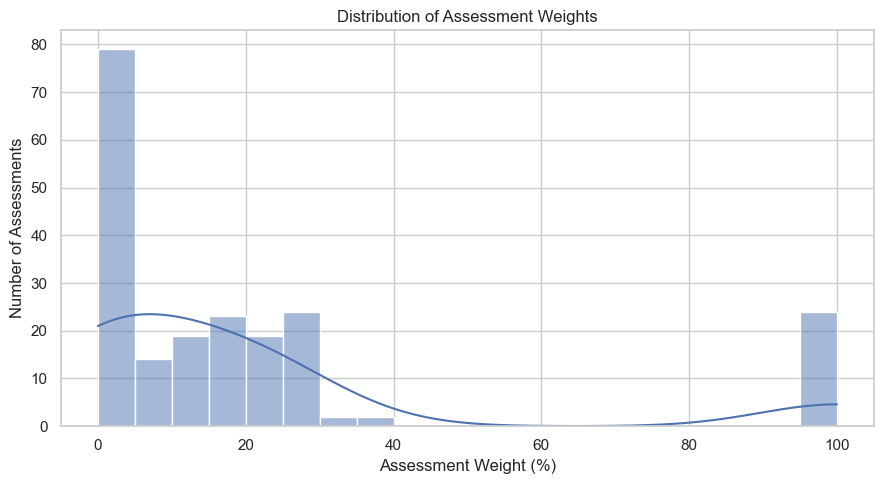

In [32]:

# 4.3. Assessment Weight Distribution

display(assessments["weight"].describe().to_frame())

plt.figure(figsize=(9, 5))
sns.histplot(
    data=assessments,
    x="weight",
    bins=20,
    kde=True
)

plt.title("Distribution of Assessment Weights")
plt.xlabel("Assessment Weight (%)")
plt.ylabel("Number of Assessments")
plt.tight_layout()
plt.show()


The histogram shows that many assessments have relatively low weights, while a separate group has a weight of 100%. The mean being higher than the median suggests a right-skewed distribution influenced by higher weight values.

These findings indicate that assessment weights vary considerably. Further analysis by course and presentation is needed to understand how assessment weights are allocated within individual courses.

### 4. Learning Behavior.

In [33]:

# 5.1. Click Count Statistics

student_vle = data["studentVle"]

print("Click count statistics:")
display(student_vle["sum_click"].describe().to_frame())

print("Total click records:", len(student_vle))
print("Total recorded clicks:", student_vle["sum_click"].sum())
print("Students:", student_vle["id_student"].nunique())
print("Learning resources:", student_vle["id_site"].nunique())


Click count statistics:


,sum_click
count,1.065528e+07
mean,3.716946e+00
std,8.849047e+00
min,1.000000e+00
25%,1.000000e+00
50%,2.000000e+00
75%,3.000000e+00
max,6.977000e+03


Total click records: 10655280
Total recorded clicks: 39605099
Students: 26074
Learning resources: 6268


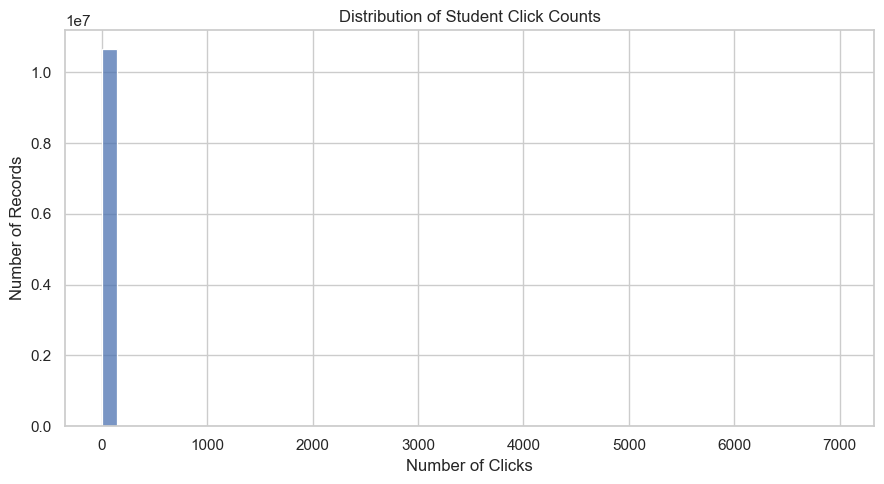

In [34]:

# 5.2. Distribution of Click Counts

plt.figure(figsize=(9, 5))

sns.histplot(
    data=student_vle,
    x="sum_click",
    bins=50
)

plt.title("Distribution of Student Click Counts")
plt.xlabel("Number of Clicks")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


,Count,Percentage
activity_type,,
resource,2660,41.80
subpage,1055,16.58
oucontent,996,15.65
url,886,13.92
forumng,194,3.05
quiz,127,2.00
page,102,1.60
oucollaborate,82,1.29
questionnaire,61,0.96


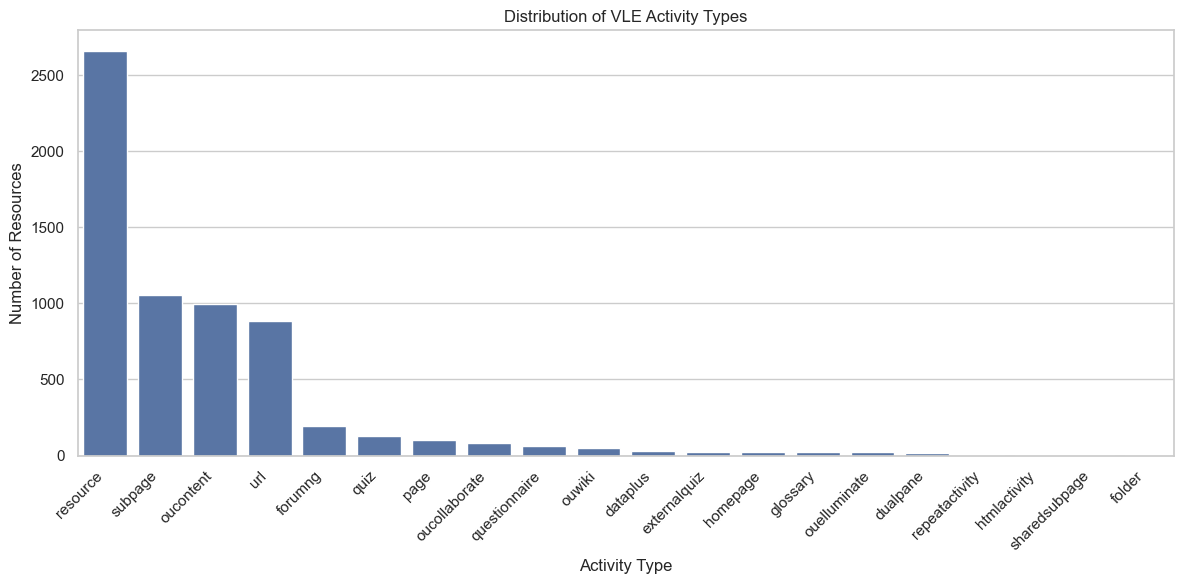

In [35]:

# 5.3. VLE Activity Types

vle = data["vle"]

activity_counts = vle["activity_type"].value_counts()

activity_summary = pd.DataFrame({
    "Count": activity_counts,
    "Percentage": (
        vle["activity_type"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(activity_summary)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=activity_counts.index,
    y=activity_counts.values
)

plt.title("Distribution of VLE Activity Types")
plt.xlabel("Activity Type")
plt.ylabel("Number of Resources")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [36]:

# 4.4. Build Learning Behavior Features

student_vle = data["studentVle"]

student_keys = [
    "id_student",
    "code_module",
    "code_presentation"
]

behavior_features = (
    student_vle
    .groupby(student_keys)
    .agg(
        total_clicks=("sum_click", "sum"),
        active_days=("date", "nunique")
    )
    .reset_index()
)

display(behavior_features.head())
print("Number of student-course records:", len(behavior_features))


,id_student,code_module,code_presentation,total_clicks,active_days
0,6516,AAA,2014J,2791,159
1,8462,DDD,2013J,646,56
2,8462,DDD,2014J,10,1
3,11391,AAA,2013J,934,40
4,23629,BBB,2013B,161,16


Number of student-course records: 29228




The `studentVle` table contains 10,655,280 interaction records and 39,605,099 recorded clicks. The mean click count per record is 3.72, while the median is 2. The distribution is strongly right-skewed, with a small number of records having very high click counts.

In the `vle` table, `resource` is the most common activity type, accounting for 41.80% of learning resources. It is followed by `subpage` (16.58%), `oucontent` (15.65%), and `url` (13.92%).

Two behavioral features, `total_clicks` and `active_days`, were constructed for each student-course-presentation combination. These features summarize the volume and frequency of recorded online interactions and can be explored further in subsequent analyses.


In [37]:

# 4.5. Interaction by Activity Type

student_vle = data["studentVle"]
vle = data["vle"]

join_keys = [
    "id_site",
    "code_module",
    "code_presentation"
]

# Keep only the columns needed for this analysis
vle_lookup = vle[
    join_keys + ["activity_type"]
].drop_duplicates()

# Join interaction records with activity types
interaction_data = student_vle.merge(
    vle_lookup,
    on=join_keys,
    how="left",
    validate="many_to_one"
)

# Summarize clicks by activity type
activity_interactions = (
    interaction_data
    .groupby("activity_type", dropna=False)
    .agg(
        total_clicks=("sum_click", "sum"),
        interaction_records=("sum_click", "size"),
        average_clicks=("sum_click", "mean")
    )
    .sort_values("total_clicks", ascending=False)
)

activity_interactions["average_clicks"] = (
    activity_interactions["average_clicks"].round(2)
)

display(activity_interactions)


,total_clicks,interaction_records,average_clicks
activity_type,,,
oucontent,11206803,1963782,5.71
forumng,7973390,2408457,3.31
quiz,6981240,914573,7.63
homepage,6949064,1735226,4.00
subpage,3411582,1949898,1.75
resource,1110132,813185,1.37
ouwiki,894512,178165,5.02
url,566702,407716,1.39
oucollaborate,108974,65793,1.66


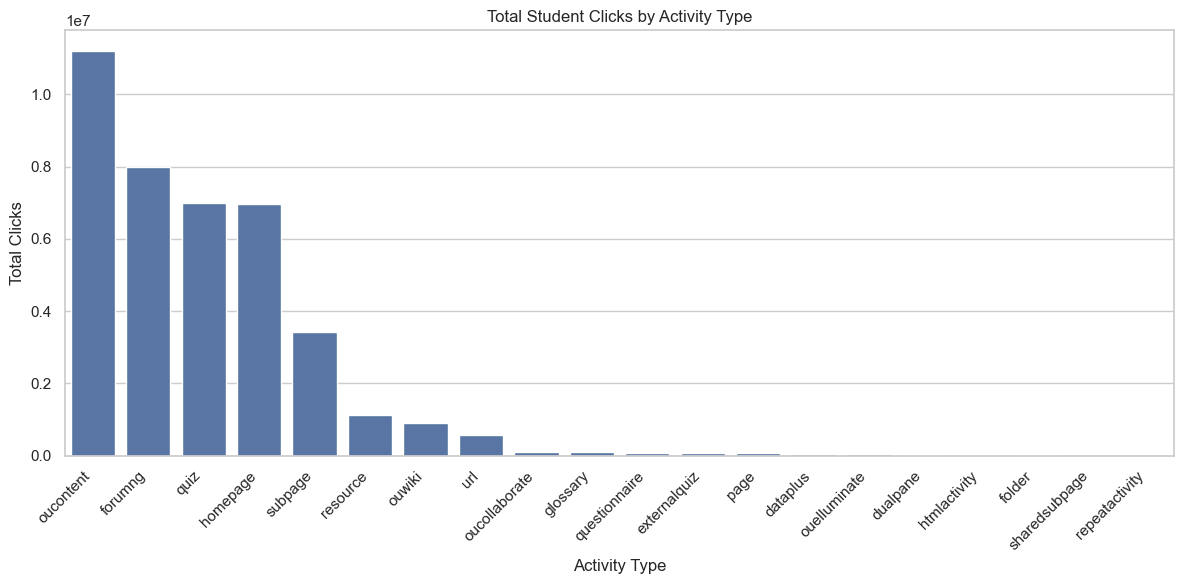

In [38]:

clicks_by_type = activity_interactions.sort_values(
    "total_clicks",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=clicks_by_type.index,
    y=clicks_by_type["total_clicks"]
)

plt.title("Total Student Clicks by Activity Type")
plt.xlabel("Activity Type")
plt.ylabel("Total Clicks")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


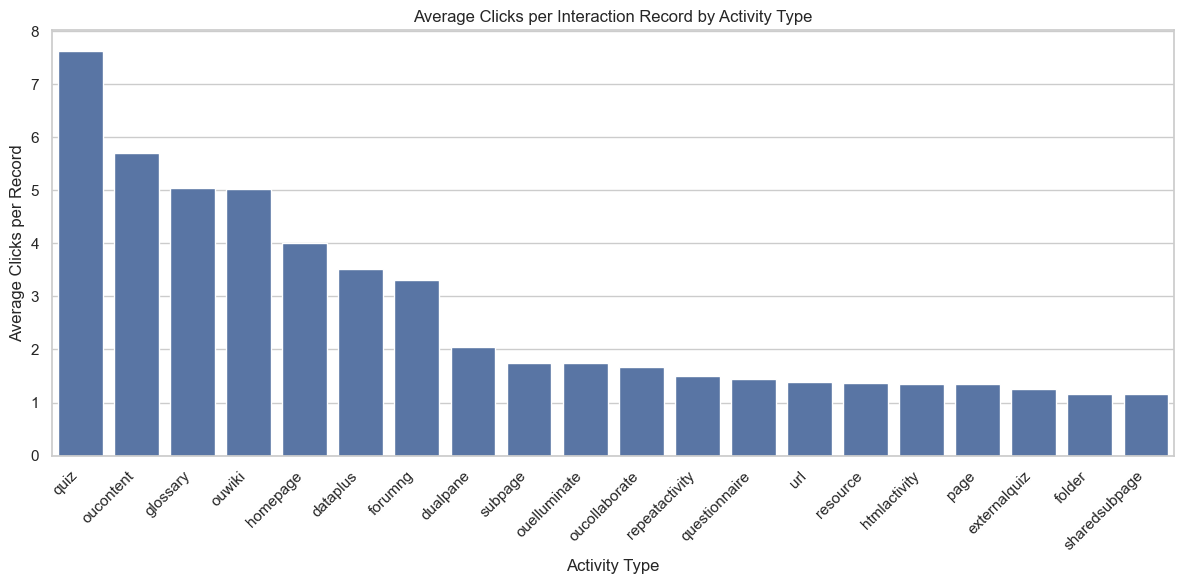

In [39]:

# 4.6. Average Clicks by Activity Type

average_by_type = activity_interactions.sort_values(
    "average_clicks",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=average_by_type.index,
    y=average_by_type["average_clicks"]
)

plt.title("Average Clicks per Interaction Record by Activity Type")
plt.xlabel("Activity Type")
plt.ylabel("Average Clicks per Record")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



The average click analysis shows that `quiz` has the highest average number of clicks per interaction record, at approximately 7.63, followed by `oucontent` at 5.71. `glossary` and `ouwiki` also have relatively high averages, at around 5 clicks per record.

In contrast, `folder` and `sharedsubpage` have the lowest average click counts, at approximately 1.1. These differences suggest that interaction frequency varies across VLE activity types. However, click counts alone cannot determine learning effectiveness.

### 5. Academic Outcomes

In [40]:

# 5.1. Distribution of Academic Outcomes

student_info = data["studentInfo"]

outcome_summary = pd.DataFrame({
    "Count": student_info["final_result"].value_counts(),
    "Percentage": (
        student_info["final_result"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(outcome_summary)


,Count,Percentage
final_result,,
Pass,12361,37.93
Withdrawn,10156,31.16
Fail,7052,21.64
Distinction,3024,9.28


**- Academic Outcomes by Learning Behaviors.**

In [42]:

# 5.2. Merge Learning Behavior with Academic Outcomes

student_keys = [
    "id_student",
    "code_module",
    "code_presentation"
]

student_info = data["studentInfo"]

behavior_outcomes = behavior_features.merge(
    student_info[
        student_keys + ["final_result"]
    ],
    on=student_keys,
    how="inner",
    validate="one_to_one"
)

print("Matched student-course records:", len(behavior_outcomes))
display(behavior_outcomes.head())


Matched student-course records: 29228


,id_student,code_module,code_presentation,total_clicks,active_days,final_result
0,6516,AAA,2014J,2791,159,Pass
1,8462,DDD,2013J,646,56,Withdrawn
2,8462,DDD,2014J,10,1,Withdrawn
3,11391,AAA,2013J,934,40,Pass
4,23629,BBB,2013B,161,16,Fail


In [ ]:

# 5.3.Learning Behavior by Final Result

behavior_summary = (
    behavior_outcomes
    .groupby("final_result")
    .agg(
        records=("id_student", "size"),
        mean_total_clicks=("total_clicks", "mean"),
        median_total_clicks=("total_clicks", "median"),
        mean_active_days=("active_days", "mean"),
        median_active_days=("active_days", "median")
    )
    .round(2)
)

display(behavior_summary)


,records,mean_total_clicks,median_total_clicks,mean_active_days,median_active_days
final_result,,,,,
Distinction,3024,2666.76,1896.0,110.04,103.0
Fail,6678,688.36,353.0,35.04,24.0
Pass,12358,1922.28,1343.0,87.07,78.0
Withdrawn,7168,444.82,221.5,23.08,15.0


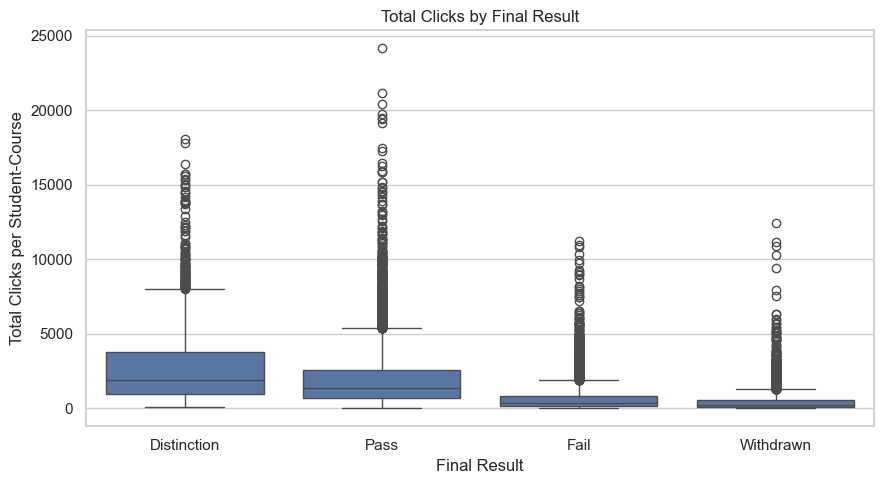

In [ ]:

# 5.4. Total Clicks by Final Result

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=behavior_outcomes,
    x="final_result",
    y="total_clicks",
    order=["Distinction", "Pass", "Fail", "Withdrawn"]
)

plt.title("Total Clicks by Final Result")
plt.xlabel("Final Result")
plt.ylabel("Total Clicks per Student-Course")
plt.tight_layout()
plt.show()



The analysis reveals a clear association between online learning engagement and final academic outcomes. Students in the `Distinction` category have the highest mean total clicks (2,666.76) and mean active days (110.04), followed by students in the `Pass` category. In contrast, students in the `Fail` and `Withdrawn` categories show substantially lower engagement levels.

The boxplot also shows right-skewed distributions with numerous high-value outliers across all outcome groups. Although these results suggest that greater online engagement is associated with better academic outcomes, they do not establish a causal relationship.

**-Academic Outcomes by Age Group**

In [ ]:

# 5.5. Final Results by Age Group

student_info = data["studentInfo"]

age_result_counts = pd.crosstab(
    student_info["age_band"],
    student_info["final_result"]
)

age_result_percentages = (
    pd.crosstab(
        student_info["age_band"],
        student_info["final_result"],
        normalize="index"
    ) * 100
).round(2)

print("Number of students:")
display(age_result_counts)

print("Percentage within each age group (%):")
display(age_result_percentages)


Number of students:


final_result,Distinction,Fail,Pass,Withdrawn
age_band,,,,
0-35,1863,5231,8469,7381
35-55,1120,1792,3800,2721
55<=,41,29,92,54


Percentage within each age group (%):


final_result,Distinction,Fail,Pass,Withdrawn
age_band,,,,
0-35,8.12,22.80,36.91,32.17
35-55,11.87,19.00,40.28,28.85
55<=,18.98,13.43,42.59,25.00


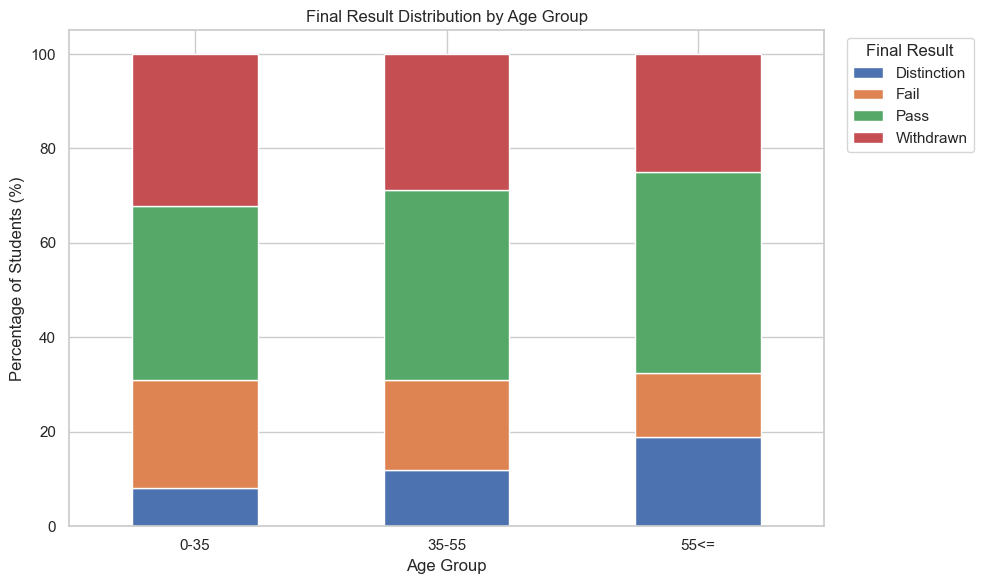

In [ ]:

# 5.6. Outcome Distribution by Age Group

age_result_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Final Result Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Students (%)")
plt.legend(title="Final Result", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



The analysis shows differences in academic outcomes across age groups. The proportion of `Distinction` increases from 8.12% in the 0–35 age group to 18.98% in the 55-and-above group. The `Pass` rate also increases, while the proportions of `Fail` and `Withdrawn` decrease across the age groups.

However, the oldest group contains substantially fewer students than the other groups. Therefore, these differences should be interpreted cautiously and do not establish a causal relationship between age and academic performance.

**-Academic Outcomes by Gender**

In [52]:

# 5.7. Final Results by Gender

student_info = data["studentInfo"]

gender_counts = pd.crosstab(
    student_info["gender"],
    student_info["final_result"]
)

gender_percentages = (
    pd.crosstab(
        student_info["gender"],
        student_info["final_result"],
        normalize="index"
    ) * 100
).round(2)

print("Number of students:")
display(gender_counts)

print("Percentage within each gender (%):")
display(gender_percentages)


Number of students:


final_result,Distinction,Fail,Pass,Withdrawn
gender,,,,
F,1394,3103,5735,4486
M,1630,3949,6626,5670


Percentage within each gender (%):


final_result,Distinction,Fail,Pass,Withdrawn
gender,,,,
F,9.47,21.08,38.97,30.48
M,9.12,22.09,37.07,31.72


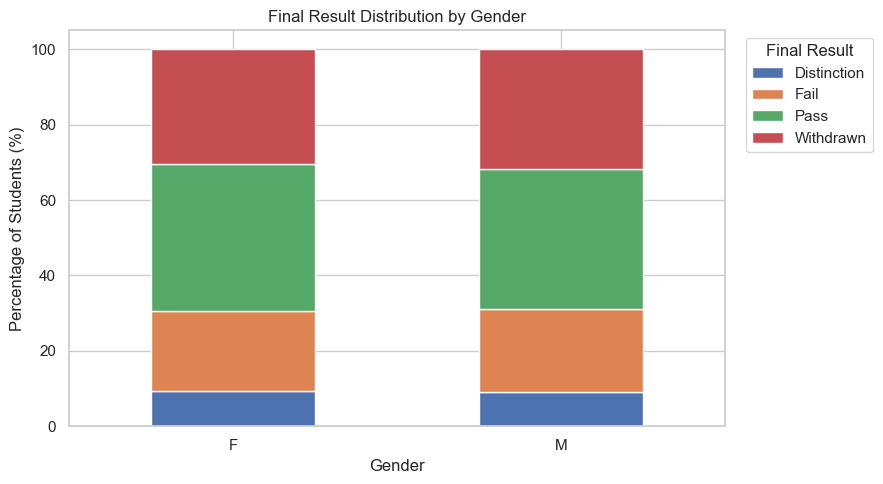

In [54]:

# 5.8. Outcome Distribution by Gender

gender_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Final Result Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage of Students (%)")
plt.legend(title="Final Result", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
